# Software Engineering for AI Developers: Computer Architecture for AI Performance

> **Who is this for:** AI developers who want to understand *why* some code is 100× faster than other code that does the same arithmetic, and students taking "Digital Logic Design", "Computer Organization and Assembly Language" (COAL) or "Computer Architecture" who want those topics connected to modern AI hardware. It also prepares you for interview questions such as "why is LLM decoding memory-bound?" and "why does bf16 not need loss scaling?".
>
> **What you will learn:**
> - **From bits to numbers:** binary, hexadecimal, **two's complement** integers and overflow, and the **IEEE-754** layouts of fp32, fp16, **bf16** and fp8, decoded bit by bit; int8 quantisation
> - **Logic gates → adders → an ALU**, simulated from a single NAND gate, and why a perceptron is a "soft" logic gate
> - **CPU basics:** the fetch–decode–execute cycle on a tiny simulated CPU, **pipelining** and hazards, and **branch prediction** (sorted vs unsorted data, measured and simulated)
> - **The memory hierarchy:** latency numbers, cache lines, a **cache-size probing** experiment, row-major vs column-major traversal, strides and `np.ascontiguousarray`
> - **SIMD and vectorisation:** Python loop vs NumPy vs numba, and the **roofline model** (compute-bound vs memory-bound) built from measurements on your machine
> - **GPU architecture concepts:** SMs, warps, memory bandwidth, tensor cores, and **arithmetic intensity of transformer layers** (why prefill is compute-bound and decoding is memory-bound)
> - **Measuring your hardware from Python** (`os`, `psutil`, `/sys`), and a **performance checklist** for AI code
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), NumPy, [Debugging and profiling](04_debugging_and_profiling.ipynb) (timing and profilers). Helpful: [Concurrency](05_concurrency_and_async.ipynb) and [Operating systems for developers](06_operating_systems_for_developers.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet, no GPU needed (GPU numbers are worked out from published specifications). Uses `numba` and `torch` if installed and skips those cells otherwise. Runs in about 1–2 minutes; timings vary between machines and runs, so the text describes trends and the cells print the exact numbers.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Patterson & Hennessy, *Computer Organization and Design* (RISC-V ed.), and Bryant & O'Hallaron, *Computer Systems: A Programmer's Perspective* (3rd ed.), ch. 2, 4, 5 and 6.

## Explained simply

A computer only understands **on** and **off** (1 and 0). Everything else (numbers, text, images, a neural network's weights) is a pattern of these bits, and the processor is a huge collection of tiny switches that combine bits according to simple rules. Knowing how numbers are stored explains why `0.1 + 0.2` is not exactly `0.3` and why AI models can be "compressed" into 8-bit or 4-bit numbers. Knowing how the processor and memory work explains a surprising fact: in most AI code the processor is **waiting for data**, not calculating. Fetching a number from main memory takes about as long as a hundred calculations, so fast code is mostly about keeping the data close to the processor and using it many times once it is there.

**Everyday analogies.**
- **The memory hierarchy** is like a kitchen: the ingredients on your counter (cache) are instant, the fridge (RAM) takes a few steps, the supermarket (disk) takes a trip. A good cook brings everything needed for a recipe to the counter at once.
- **SIMD / vectorisation** is like a cashier scanning a whole basket with one swipe instead of one item at a time.
- **Branch prediction** is like a waiter who guesses your usual order and starts preparing it before you speak: great when you are predictable, a waste when you are random.

**A tiny example.** The number 5 in 8 bits is `00000101`. To store −5, computers use **two's complement**: flip every bit (`11111010`) and add 1 → `11111011`. Now adding 5 + (−5) with ordinary binary addition gives `1 00000000`; the extra 1 falls off the end of the 8 bits and the result is `00000000` = 0, exactly right. The same adder circuit handles both positive and negative numbers.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Floating-point format (fp32, bf16, int8) | how many bits a number gets, and how they are split | training in bf16, running LLMs in 4-bit or 8-bit |
| Memory hierarchy | small fast storage close by, big slow storage far away | why LLM text generation speed depends on memory bandwidth |
| Arithmetic intensity | calculations done per byte fetched | deciding whether a GPU kernel is limited by compute or by memory |

## 0. Setup

> 💬 **In plain English:** load the tools and record what machine we are running on.

In [1]:
import math, os, platform, struct, sys, time, tracemalloc, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(0)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)


def best_time(fn, repeat=5):
    """Minimum wall time over `repeat` runs (noise from other programs only makes runs slower)."""
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return min(times)

try:
    from numba import njit
    HAVE_NUMBA = True
except ImportError:
    HAVE_NUMBA = False
try:
    import torch
    torch.set_num_threads(2)
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| machine:", platform.machine(),
      "| numba:", HAVE_NUMBA, "| torch:", HAVE_TORCH)

Python 3.12.3 | numpy 2.4.6 | machine: x86_64 | numba: True | torch: True


## 1. From bits to numbers

> 💬 **In plain English:** every number in a computer is a fixed-size bit pattern, and the layout decides its range and precision.

### 1.1 Binary, hexadecimal and unsigned integers

**Definition.** An $n$-bit **unsigned integer** $b_{n-1} \dots b_1 b_0$ has value $\sum_i b_i 2^i$, range $0 \dots 2^n - 1$. **Hexadecimal** writes 4 bits per digit (`0x0`–`0xF`), so one byte is two hex digits.

| decimal | binary (8 bits) | hex |
|---|---|---|
| 5 | `00000101` | `0x05` |
| 200 | `11001000` | `0xC8` |
| 255 | `11111111` | `0xFF` |

### 1.2 Two's complement (signed integers)

**Definition.** In $n$-bit **two's complement**, the top bit has weight $-2^{n-1}$ instead of $+2^{n-1}$: value $= -b_{n-1}2^{n-1} + \sum_{i<n-1} b_i 2^i$. Range $-2^{n-1} \dots 2^{n-1} - 1$ (int8: −128 … 127). To negate: **flip all bits and add 1**. Its big advantage: the **same adder** works for signed and unsigned numbers, and there is only one zero.

**Overflow** happens when the true result does not fit: in int8, $127 + 1$ wraps around to $-128$.

In [2]:
def to_twos(x, bits=8):
    """Bit string of integer x in `bits`-bit two's complement (x must be in range)."""
    assert -(1 << (bits - 1)) <= x < (1 << (bits - 1)), "out of range"
    return format(x & ((1 << bits) - 1), f"0{bits}b")       # masking = adding 2^bits to negatives

def from_twos(s):
    """Value of a two's-complement bit string: the top bit has weight -2^(n-1)."""
    n = len(s)
    return -int(s[0]) * (1 << (n - 1)) + int(s[1:], 2) if n > 1 else -int(s)

for x in [5, -5, 127, -128, -1, 0]:
    s = to_twos(x)
    print(f"{x:5d} -> {s}  hex 0x{int(s, 2):02X}  back -> {from_twos(s)}")
assert all(from_twos(to_twos(x)) == x for x in range(-128, 128))     # exhaustive check, all 256 values
assert to_twos(-5) == format((~5 + 1) & 0xFF, "08b")                  # "flip the bits and add 1"

a = np.array([127, 100, -128], dtype=np.int8)
print("int8 wrap-around:", a, "+ [1, 50, -1] =", a + np.array([1, 50, -1], dtype=np.int8))

    5 -> 00000101  hex 0x05  back -> 5
   -5 -> 11111011  hex 0xFB  back -> -5
  127 -> 01111111  hex 0x7F  back -> 127
 -128 -> 10000000  hex 0x80  back -> -128
   -1 -> 11111111  hex 0xFF  back -> -1
    0 -> 00000000  hex 0x00  back -> 0
int8 wrap-around: [ 127  100 -128] + [1, 50, -1] = [-128 -106  127]


**What just happened?** All 256 int8 values round-trip correctly, and negation really is "flip and add 1". NumPy integer **arrays** wrap around silently on overflow: $127 + 1 = -128$, $100 + 50 = -106$ (150 − 256) and $-128 - 1 = 127$. Python's own `int` never overflows (it grows as needed), which hides this from beginners until they use NumPy or PyTorch tensors.

⚠️ **Common mistake:** accumulating many int8 or fp16 values in the same small type. Hardware for quantised inference multiplies int8 values but **accumulates in int32** for exactly this reason.

### 1.3 IEEE-754 floating point

**Intuition.** Floating point is scientific notation in base 2: $-1.0110_2 \times 2^{3}$. A fixed number of bits is split between the **exponent** (range) and the **mantissa** (precision).

**Definition.** A normal IEEE-754 binary number is stored as sign $s$, biased exponent $e$ and fraction $f$, with value
$$(-1)^s \times 1.f_2 \times 2^{\,e - \text{bias}}, \qquad \text{bias} = 2^{k-1} - 1 \text{ for a } k\text{-bit exponent}.$$
Exponent all zeros means **subnormal** numbers (no hidden 1) and zero; all ones means **infinity** or **NaN**.

| Format | Total bits | Sign | Exponent | Mantissa (stored) | Typical AI use |
|---|---|---|---|---|---|
| fp32 (single) | 32 | 1 | 8 | 23 | default training precision, accumulators |
| fp16 (half) | 16 | 1 | 5 | 10 | inference, mixed-precision training (needs loss scaling) |
| **bf16** (bfloat16) | 16 | 1 | 8 | 7 | mixed-precision training on TPUs/GPUs: fp32's range, less precision |
| fp8 E4M3 / E5M2 | 8 | 1 | 4 / 5 | 3 / 2 | forward / backward passes on H100-class GPUs |

**Worked example by hand: 0.15625 in fp32.** $0.15625 = 1/8 + 1/32 = 0.00101_2 = 1.01_2 \times 2^{-3}$. Sign 0; exponent $-3 + 127 = 124 = $ `01111100`; fraction `0100…0`. Bits: `0 01111100 01000000000000000000000` = `0x3E200000`.

In [3]:
def fp32_fields(x):
    """Split a float into the sign, exponent and fraction fields of its fp32 encoding."""
    bits = struct.unpack(">I", struct.pack(">f", x))[0]       # reinterpret the 4 bytes as an unsigned int
    s, e, f = bits >> 31, (bits >> 23) & 0xFF, bits & 0x7FFFFF
    if e == 0:
        value = (-1) ** s * (f / 2 ** 23) * 2 ** -126           # subnormal (or zero)
    elif e == 0xFF:
        value = float("nan") if f else (-1) ** s * math.inf
    else:
        value = (-1) ** s * (1 + f / 2 ** 23) * 2 ** (e - 127)  # normal: hidden leading 1
    return f"{s} {e:08b} {f:023b}", f"0x{bits:08X}", e - 127, value

rows = []
for x in [0.15625, 1.0, -2.5, 0.1, 3.4e38, 1e-45]:
    b, h, exp, v = fp32_fields(x)
    rows.append((x, b, h, exp, v))
print(pd.DataFrame(rows, columns=["x", "sign exponent fraction", "hex", "unbiased exp", "decoded value"]).to_string(index=False))
assert fp32_fields(0.15625)[1] == "0x3E200000"
print("\n0.1 stored in fp32 is exactly", f"{fp32_fields(0.1)[3]:.20f}")
print("0.1 + 0.2 == 0.3 in float64?", 0.1 + 0.2 == 0.3, "| difference:", (0.1 + 0.2) - 0.3)

            x             sign exponent fraction        hex  unbiased exp  decoded value
 1.562500e-01 0 01111100 01000000000000000000000 0x3E200000            -3   1.562500e-01
 1.000000e+00 0 01111111 00000000000000000000000 0x3F800000             0   1.000000e+00
-2.500000e+00 1 10000000 01000000000000000000000 0xC0200000             1  -2.500000e+00
 1.000000e-01 0 01111011 10011001100110011001101 0x3DCCCCCD            -4   1.000000e-01
 3.400000e+38 0 11111110 11111111100100110011110 0x7F7FC99E           127   3.400000e+38
 1.000000e-45 0 00000000 00000000000000000000001 0x00000001          -127   1.401298e-45

0.1 stored in fp32 is exactly 0.10000000149011611938
0.1 + 0.2 == 0.3 in float64? False | difference: 5.551115123125783e-17


**What just happened?** The decoder reproduces the hand-worked `0x3E200000`. `0.1` has no finite binary expansion (like 1/3 in decimal), so it is stored as the nearest representable value, slightly above 0.1. That is why `0.1 + 0.2 == 0.3` is `False`: compare floats with a tolerance (`math.isclose`, `np.allclose`). The largest value shown (3.4e38) is near fp32's maximum, and `1e-45` became the smallest **subnormal** (exponent field 0).

Now let us compare the formats AI actually uses. We compute range and precision from the bit layouts, check them against `np.finfo` / `torch.finfo`, and see what goes wrong in low precision.

In [4]:
def fmt_props(exp_bits, man_bits):
    """Largest finite value, smallest normal value and machine epsilon of an IEEE-style binary format."""
    bias = 2 ** (exp_bits - 1) - 1
    max_val = (2 - 2.0 ** -man_bits) * 2.0 ** bias            # largest exponent field 2^k - 2
    min_normal = 2.0 ** (1 - bias)
    eps = 2.0 ** -man_bits                                     # gap between 1 and the next number
    return max_val, min_normal, eps, man_bits * math.log10(2) + math.log10(2)   # ~decimal digits

rows = []
for name, e, m in [("fp32", 8, 23), ("fp16", 5, 10), ("bf16", 8, 7)]:
    mx, mn, eps, digits = fmt_props(e, m)
    rows.append((name, e, m, mx, mn, eps, round(digits, 1)))
fmt = pd.DataFrame(rows, columns=["format", "exp bits", "mantissa bits", "max", "min normal", "epsilon", "≈ decimal digits"])
print(fmt.to_string(index=False))

assert fmt_props(8, 23)[0] == float(np.finfo(np.float32).max) and fmt_props(5, 10)[0] == float(np.finfo(np.float16).max)
assert fmt_props(8, 23)[2] == float(np.finfo(np.float32).eps) and fmt_props(5, 10)[2] == float(np.finfo(np.float16).eps)
if HAVE_TORCH:
    fb = torch.finfo(torch.bfloat16)
    assert (fb.max, fb.tiny, fb.eps) == fmt_props(8, 7)[:3]
    print("bf16 matches torch.finfo:", fb.max, fb.tiny, fb.eps)
    f8 = getattr(torch, "float8_e4m3fn", None)
    if f8 is not None:
        print("fp8 E4M3 (torch.float8_e4m3fn): max", torch.finfo(f8).max, "| eps", torch.finfo(f8).eps,
              "(E4M3 'fn' drops infinities to reach 448)")

format  exp bits  mantissa bits          max   min normal      epsilon  ≈ decimal digits
  fp32         8             23 3.402823e+38 1.175494e-38 1.192093e-07               7.2
  fp16         5             10 6.550400e+04 6.103516e-05 9.765625e-04               3.3
  bf16         8              7 3.389531e+38 1.175494e-38 7.812500e-03               2.4
bf16 matches torch.finfo: 3.3895313892515355e+38 1.1754943508222875e-38 0.0078125
fp8 E4M3 (torch.float8_e4m3fn): max 448.0 | eps 0.125 (E4M3 'fn' drops infinities to reach 448)


In [5]:
def to_bf16(x):
    """Round fp32 values to bf16 (keep the top 16 bits), using round-to-nearest-even, returned as fp32."""
    b = np.asarray(x, dtype=np.float32).view(np.uint32).astype(np.uint64)
    rounding = 0x7FFF + ((b >> 16) & 1)                       # ties go to the even neighbour
    return ((b + rounding) >> 16 << 16).astype(np.uint32).view(np.float32)

x = np.random.default_rng(0).normal(0, 100, 10_000).astype(np.float32)
if HAVE_TORCH:
    ref = torch.tensor(x).to(torch.bfloat16).to(torch.float32).numpy()
    assert (to_bf16(x) == ref).all()
    print("our bf16 rounding matches torch on 10,000 random values")

print("\nWhat goes wrong in 16 bits:")
with np.errstate(over="ignore"):                                  # the overflow is the point: silence the warning
    print("  fp16 overflow: 300 * 300 =", np.float16(300) * np.float16(300), "| bf16:", to_bf16(np.float32(90_000.0)))
print("  fp16 underflow: 1e-8 ->", np.float16(1e-8), "| bf16:", to_bf16(np.float32(1e-8)))
acc16, acc32 = np.float16(0), np.float32(0)
for _ in range(5000):
    acc16 = np.float16(acc16 + np.float16(1)); acc32 += np.float32(1)
print(f"  adding 1.0 five thousand times: fp16 total = {acc16}, fp32 total = {acc32}")
print("  why: in fp16 the gap between neighbouring numbers at 2048 is", np.spacing(np.float16(2048)))

our bf16 rounding matches torch on 10,000 random values

What goes wrong in 16 bits:
  fp16 overflow: 300 * 300 = inf | bf16: 90112.0
  fp16 underflow: 1e-8 -> 0.0 | bf16: 1.0011718e-08
  adding 1.0 five thousand times: fp16 total = 2048.0, fp32 total = 5000.0
  why: in fp16 the gap between neighbouring numbers at 2048 is 2.0


**What just happened?**
- The formulas from the bit layout reproduce `np.finfo` and `torch.finfo` exactly: fp16 tops out at **65,504**, while bf16 keeps fp32's 8-bit exponent and so reaches about $3.4 \times 10^{38}$ with only ~2–3 significant decimal digits.
- fp16 **overflows** at 300 × 300 = 90,000 (→ `inf`) and **underflows** tiny gradients like $10^{-8}$ to 0. bf16 handles both (coarsely). This is why fp16 mixed-precision training needs **loss scaling** (multiply the loss so small gradients do not vanish) and bf16 usually does not.
- Adding 1.0 repeatedly in fp16 gets **stuck at 2048**: there the gap between neighbouring fp16 numbers is 2, so $2048 + 1$ rounds back to 2048. Mixed-precision training therefore keeps **fp32 master weights** and **fp32 accumulators**.

### 1.4 Integer quantisation (int8)

**Definition.** **Symmetric linear quantisation** maps a real tensor $x$ to int8 with a **scale** $s = \max|x| / 127$: $q = \text{round}(x / s)$, clipped to $[-127, 127]$; dequantise with $\hat{x} = s \cdot q$. Storage drops 4× versus fp32, and int8 multiply-accumulate units are much cheaper than float ones. Deeper treatment: [`14_Mathematics/08`](../14_Mathematics/08_industry_math_in_practice.ipynb) (floating point in practice) and [`05_Deep_Learning/13`](../05_Deep_Learning/13_quantization_and_compression_advanced.ipynb) (GPTQ, AWQ, 4-bit).

In [6]:
w = np.random.default_rng(1).normal(0, 0.02, (256, 256)).astype(np.float32)   # weights of a layer
xin = np.random.default_rng(2).normal(0, 1, 256).astype(np.float32)

scale = np.abs(w).max() / 127
q = np.clip(np.round(w / scale), -127, 127).astype(np.int8)                  # 1 byte per weight
w_hat = q.astype(np.float32) * scale
y_ref = w @ xin
y_int = (q.astype(np.int32) @ np.round(xin / (np.abs(xin).max() / 127)).astype(np.int32)) * scale * (np.abs(xin).max() / 127)
print(f"bytes: fp32 {w.nbytes:,} -> int8 {q.nbytes:,} (4x smaller)")
print(f"max weight error {np.abs(w - w_hat).max():.2e} (at most scale/2 = {scale / 2:.2e})")
print(f"layer output relative error with int8 weights AND activations, int32 accumulation: "
      f"{np.linalg.norm(y_int - y_ref) / np.linalg.norm(y_ref):.4f}")
assert np.abs(w - w_hat).max() <= scale / 2 + 1e-9

bytes: fp32 262,144 -> int8 65,536 (4x smaller)
max weight error 3.47e-04 (at most scale/2 = 3.47e-04)
layer output relative error with int8 weights AND activations, int32 accumulation: 0.0127


**What just happened?** Each weight now takes 1 byte instead of 4, every rounding error is at most half a quantisation step (asserted), and a whole layer computed with int8 inputs and **int32 accumulation** stays within about one percent of the fp32 result (the exact relative error is printed). Outliers make $\max|x|$ large and the steps coarse, which is why LLM quantisers use per-channel or per-group scales.

🎓 **Interview tip:** "bf16 vs fp16?" Same size; bf16 trades 3 bits of mantissa for 3 bits of exponent, so it has fp32's **range** (no loss scaling, fewer overflows) but less **precision**. fp16 is more precise for values in a known small range, which suits inference.

## 2. Logic gates → adders → an ALU

> 💬 **In plain English:** a single kind of switch (NAND) is enough to build circuits that add and compare numbers.

**Intuition.** A transistor is a switch. A few switches make a **logic gate**; gates make an **adder**; adders plus a few more gates make the **arithmetic logic unit (ALU)** that does every addition in your CPU.

**Definitions.** A **logic gate** computes a Boolean function. **NAND** ("not and") is **functionally complete**: every Boolean function can be built from NAND alone.

| A | B | NAND | AND | OR | XOR |
|---|---|---|---|---|---|
| 0 | 0 | 1 | 0 | 0 | 0 |
| 0 | 1 | 1 | 0 | 1 | 1 |
| 1 | 0 | 1 | 0 | 1 | 1 |
| 1 | 1 | 0 | 1 | 1 | 0 |

A **half adder** adds two bits: sum = A XOR B, carry = A AND B. A **full adder** also takes a carry-in: sum = A ⊕ B ⊕ Cin, Cout = AB + Cin(A ⊕ B). Chaining $n$ full adders gives an $n$-bit **ripple-carry adder**: each carry waits for the previous one, so its delay grows as $O(n)$ gate delays.

In [7]:
GATES = Counter()                                    # how many NAND gates were evaluated

def NAND(a, b):
    GATES["nand"] += 1
    return 1 - (a & b)
def NOT(a):     return NAND(a, a)
def AND(a, b):  return NOT(NAND(a, b))
def OR(a, b):   return NAND(NOT(a), NOT(b))                     # De Morgan
def XOR(a, b):
    n = NAND(a, b)
    return NAND(NAND(a, n), NAND(b, n))                          # the classic 4-NAND XOR

def full_adder(a, b, cin):
    s1 = XOR(a, b)
    return XOR(s1, cin), OR(AND(a, b), AND(s1, cin))             # (sum, carry out)

def ripple_add(A, B, cin=0):
    """Add two little-endian bit lists with a chain of full adders. Returns (sum bits, carry out)."""
    out, c = [], cin
    for a, b in zip(A, B):
        s, c = full_adder(a, b, c)
        out.append(s)
    return out, c

bits = lambda x, n=8: [(x >> i) & 1 for i in range(n)]           # little-endian bit list
value = lambda bs: sum(b << i for i, b in enumerate(bs))

truth = pd.DataFrame([(a, b, NAND(a, b), AND(a, b), OR(a, b), XOR(a, b)) for a in (0, 1) for b in (0, 1)],
                     columns=["A", "B", "NAND", "AND", "OR", "XOR"])
print(truth.to_string(index=False))
GATES.clear()
for x in range(256):                                              # exhaustive: all 65,536 pairs of bytes
    for y in range(256):
        s, c = ripple_add(bits(x), bits(y))
        assert value(s) + (c << 8) == x + y
print(f"8-bit ripple-carry adder correct on all 65,536 input pairs; NAND gates per addition: {GATES['nand'] // 65536}")

 A  B  NAND  AND  OR  XOR
 0  0     1    0   0    0
 0  1     1    0   1    1
 1  0     1    0   1    1
 1  1     0    1   1    0


8-bit ripple-carry adder correct on all 65,536 input pairs; NAND gates per addition: 120


**What just happened?** Built from nothing but NAND, the 8-bit adder is correct on every one of the 65,536 input pairs. Each addition evaluated a fixed number of NAND gates (printed above), and in hardware these switch in nanoseconds.

Now the **ALU**. Subtraction reuses the adder: $A - B = A + (\text{NOT } B) + 1$, the two's-complement trick from section 1. The ALU also outputs **flags** that the CPU uses for comparisons and branches: **Z** (result is zero), **N** (negative: top bit set), **C** (carry out, unsigned overflow) and **V** (signed overflow: the inputs had the same sign but the result's sign differs).

In [8]:
def alu(op, x, y, n=8):
    """A tiny n-bit ALU built from the gate functions. Returns (result as unsigned int, flags dict)."""
    A, B = bits(x, n), bits(y, n)
    if op == "ADD":
        R, c = ripple_add(A, B, 0)
    elif op == "SUB":
        R, c = ripple_add(A, [NOT(b) for b in B], 1)          # A + ~B + 1
    elif op in ("AND", "OR", "XOR"):
        g = {"AND": AND, "OR": OR, "XOR": XOR}[op]
        R, c = [g(a, b) for a, b in zip(A, B)], 0
    else:
        raise ValueError(op)
    sa, sb, sr = A[-1], (B[-1] if op == "ADD" else NOT(B[-1])), R[-1]
    flags = {"Z": int(value(R) == 0), "N": sr, "C": c,
             "V": int(op in ("ADD", "SUB") and sa == sb and sr != sa)}
    return value(R), flags

signed = lambda u, n=8: u - (1 << n) if u >> (n - 1) else u
rng = np.random.default_rng(0)
for _ in range(3000):
    x, y = (int(v) for v in rng.integers(0, 256, 2))
    for op, ref in [("ADD", x + y), ("SUB", x - y), ("AND", x & y), ("OR", x | y), ("XOR", x ^ y)]:
        r, f = alu(op, x, y)
        assert r == ref & 0xFF and f["Z"] == (r == 0)
        if op in ("ADD", "SUB"):
            true_signed = signed(x) + signed(y) if op == "ADD" else signed(x) - signed(y)
            assert f["V"] == int(not -128 <= true_signed <= 127)            # signed overflow flag
for op, x, y in [("ADD", 100, 50), ("SUB", 5, 7), ("SUB", 9, 9), ("ADD", 200, 100)]:
    r, f = alu(op, x, y)
    print(f"{op} {x:3d}, {y:3d} -> {r:3d} (signed {signed(r):4d})  flags {f}")

ADD 100,  50 -> 150 (signed -106)  flags {'Z': 0, 'N': 1, 'C': 0, 'V': 1}
SUB   5,   7 -> 254 (signed   -2)  flags {'Z': 0, 'N': 1, 'C': 0, 'V': 0}
SUB   9,   9 ->   0 (signed    0)  flags {'Z': 1, 'N': 0, 'C': 1, 'V': 0}
ADD 200, 100 ->  44 (signed   44)  flags {'Z': 0, 'N': 0, 'C': 1, 'V': 0}


**What just happened?** The ALU agrees with Python on 3,000 random byte pairs for all five operations, and its **V** flag fires exactly when the signed result leaves −128…127 (asserted). In the examples, `100 + 50` sets V (150 does not fit in int8, the same wrap-around as in section 1), `5 − 7` gives −2 with N set, `9 − 9` sets Z, and `200 + 100` sets C (unsigned overflow). A compare-and-branch instruction such as `if a < b` is just a subtraction whose result is thrown away and whose flags are kept.

🔗 **Faster adders are parallel prefix sums.** A ripple-carry adder has $O(n)$ delay. A **carry-lookahead** (e.g. Kogge–Stone) adder computes all carries with a **parallel prefix scan** over (generate, propagate) pairs in $O(\log n)$ gate delays: the same scan as in [`advanced_algorithms/10`](../00_AI_Fundamentals/advanced_algorithms/10_parallel_and_external_memory_algorithms.ipynb). Practice problem 4 builds one.

### 2.1 A perceptron is a "soft" logic gate

A perceptron outputs $\text{step}(w_1 x_1 + w_2 x_2 + b)$. With the right weights it **is** a logic gate; replacing the step with a sigmoid $\sigma(k \cdot (w \cdot x + b))$ gives a smooth, trainable version that approaches the hard gate as $k$ grows. XOR, however, is not **linearly separable**, so no single perceptron computes it; two layers (OR and NAND feeding AND) do. This is the historical argument (Minsky & Papert, 1969) for hidden layers.

In [9]:
step = lambda z: (z > 0).astype(int)
sigmoid = lambda z: 1 / (1 + np.exp(-z))
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
gates = {"AND": ([1, 1], -1.5), "OR": ([1, 1], -0.5), "NAND": ([-1, -1], 1.5)}
for name, (wt, b) in gates.items():
    z = X @ np.array(wt) + b
    print(f"{name:4s} perceptron: {step(z).tolist()} | soft version k=10: {np.round(sigmoid(10 * z), 3).tolist()}")
    assert step(z).tolist() == [ {"AND": a & c, "OR": a | c, "NAND": 1 - (a & c)}[name] for a, c in X ]

# No single perceptron computes XOR: search a grid of 41^3 weight settings
grid = np.linspace(-2, 2, 41)
found = any((step(X @ np.array([w1, w2]) + b) == [0, 1, 1, 0]).all() for w1 in grid for w2 in grid for b in grid)
print("single perceptron for XOR found on the grid:", found)
h1, h2 = step(X @ np.array([1, 1]) - 0.5), step(X @ np.array([-1, -1]) + 1.5)       # hidden layer: OR, NAND
xor = step(np.stack([h1, h2], 1) @ np.array([1, 1]) - 1.5)                        # output: AND
print("two-layer network (OR, NAND -> AND) gives XOR:", xor.tolist())
assert xor.tolist() == [0, 1, 1, 0] and not found

AND  perceptron: [0, 0, 0, 1] | soft version k=10: [0.0, 0.007, 0.007, 0.993]
OR   perceptron: [0, 1, 1, 1] | soft version k=10: [0.007, 0.993, 0.993, 1.0]
NAND perceptron: [1, 1, 1, 0] | soft version k=10: [1.0, 0.993, 0.993, 0.007]


single perceptron for XOR found on the grid: False
two-layer network (OR, NAND -> AND) gives XOR: [0, 1, 1, 0]


## 3. CPU basics: fetch–decode–execute, pipelining and branch prediction

> 💬 **In plain English:** a CPU repeats fetch, decode, execute; pipelining overlaps these steps, and guessing branches keeps the pipeline full.

### 3.1 The fetch–decode–execute cycle

**Definition.** A CPU repeatedly (1) **fetches** the instruction at the address in the **program counter (PC)**, (2) **decodes** it (which operation, which registers), (3) **executes** it in the ALU or reads/writes memory, (4) writes the result back to a **register** and advances the PC (or jumps, for a branch). Registers are a handful of tiny storage slots inside the CPU, the fastest memory there is.

Below is a toy CPU with 4 registers and a RISC-style instruction set, running a **dot product**, the core operation of every neural network.

| Instruction | Meaning |
|---|---|
| `LI rd, imm` | rd ← imm (load immediate) |
| `LD rd, rs, base` | rd ← memory[base + rs] |
| `MUL rd, rs, rt` / `ADD rd, rs, rt` | rd ← rs × rt / rs + rt |
| `ADDI rd, rs, imm` | rd ← rs + imm |
| `BNE rs, rt, label` | if rs ≠ rt, jump to label |
| `HALT` | stop |

In [10]:
def run_cpu(program, memory, max_steps=10_000):
    """Interpret a list of instructions. Returns final registers and a trace of every executed instruction."""
    R = [0, 0, 0, 0]                                         # registers R0..R3
    pc, trace = 0, []
    labels = {ins[1]: i for i, ins in enumerate(program) if ins[0] == "LABEL"}
    while len(trace) < max_steps:
        ins = program[pc]                                     # FETCH
        op, *args = ins                                       # DECODE
        next_pc = pc + 1
        if op == "LABEL":
            pc = next_pc; continue
        if op == "LI":   R[args[0]] = args[1]                 # EXECUTE + WRITE BACK
        elif op == "LD":   R[args[0]] = memory[args[2] + R[args[1]]]
        elif op == "MUL":  R[args[0]] = R[args[1]] * R[args[2]]
        elif op == "ADD":  R[args[0]] = R[args[1]] + R[args[2]]
        elif op == "ADDI": R[args[0]] = R[args[1]] + args[2]
        elif op == "BNE":
            if R[args[0]] != R[args[1]]:
                next_pc = labels[args[2]]
        trace.append((pc, " ".join(map(str, ins)), *R, next_pc != pc + 1))
        if op == "HALT":
            break
        pc = next_pc
    return R, pd.DataFrame(trace, columns=["pc", "instruction", "R0", "R1", "R2", "R3", "branch taken"])

# memory: vector a at 0..3, vector b at 4..7.  R0 = i, R1 = acc, R2/R3 = temporaries.
memory = [1, 2, 3, 4, 10, 20, 30, 40]
dot_program = [
    ("LI", 0, 0), ("LI", 1, 0),                          # i = 0, acc = 0
    ("LABEL", "loop"),
    ("LD", 2, 0, 0), ("LD", 3, 0, 4),                    # R2 = a[i], R3 = b[i]
    ("MUL", 2, 2, 3), ("ADD", 1, 1, 2),                  # acc += a[i] * b[i]
    ("ADDI", 0, 0, 1),                                   # i += 1
    ("LI", 3, 4), ("BNE", 0, 3, "loop"),                 # if i != 4: goto loop
    ("HALT",),
]
R, trace = run_cpu(dot_program, memory)
print("dot product =", R[1], "| NumPy:", int(np.dot(memory[:4], memory[4:])), "| instructions executed:", len(trace))
assert R[1] == np.dot(memory[:4], memory[4:])
trace.head(10)

dot product = 300 | NumPy: 300 | instructions executed: 31


,pc,instruction,R0,R1,R2,R3,branch taken
0,0,LI 0 0,0,0,0,0,False
1,1,LI 1 0,0,0,0,0,False
2,3,LD 2 0 0,0,0,1,0,False
3,4,LD 3 0 4,0,0,1,10,False
4,5,MUL 2 2 3,0,0,10,10,False
5,6,ADD 1 1 2,0,10,10,10,False
6,7,ADDI 0 0 1,1,10,10,10,False
7,8,LI 3 4,1,10,10,4,False
8,9,BNE 0 3 loop,1,10,10,4,True
9,3,LD 2 0 0,1,10,2,4,False


**What just happened?** The toy CPU computed $1 \cdot 10 + 2 \cdot 20 + 3 \cdot 30 + 4 \cdot 40 = 300$ by executing simple instructions one at a time; the trace shows the registers after each one. A real CPU does the same thing billions of times per second, and a GPU does it with thousands of lanes at once.

### 3.2 Pipelining and hazards

**Intuition.** A laundry with a washer, a dryer and a folding table: while load 1 dries, load 2 can already wash. Each load still takes the same time, but a finished load comes out every step.

**Definition.** A classic 5-stage RISC pipeline overlaps **IF** (fetch), **ID** (decode), **EX** (execute), **MEM** (memory access) and **WB** (write back). Ideally $n$ instructions take $n + 4$ cycles instead of $5n$ (CPI → 1).

```
cycle:   1   2   3   4   5   6   7
instr 1  IF  ID  EX  MEM WB
instr 2      IF  ID  EX  MEM WB
instr 3          IF  ID  EX  MEM WB
```

**Hazards** break the ideal: a **data hazard** (an instruction needs a value a previous one has not produced yet; with forwarding, only a **load followed immediately by a use** costs a 1-cycle stall), a **control hazard** (after a branch, which instruction comes next? without prediction, wait; with prediction, guess and flush on a mistake), and a **structural hazard** (two instructions want the same hardware unit).

We can count the hazards in our trace and estimate the cycles under simple assumptions: 5 stages, forwarding, 1 stall per load-use pair, 2 cycles lost per **mispredicted** branch.

In [11]:
instrs = [tuple(s.split()) for s in trace["instruction"]]
load_use = sum(1 for prev, cur in zip(instrs, instrs[1:])
               if prev[0] == "LD" and len(cur) > 2 and prev[1] in cur[2:])     # next instruction reads the loaded register
taken = int(trace["branch taken"].sum())
n_br = sum(1 for ins in instrs if ins[0] == "BNE")
n = len(instrs)
rows = [("no pipeline (5 cycles each)", 5 * n),
        ("ideal pipeline", n + 4),
        ("pipeline, stall on every branch", n + 4 + load_use + 2 * n_br),
        ("pipeline, predict 'taken' (wrong only on loop exit)", n + 4 + load_use + 2 * (n_br - taken))]
pipe = pd.DataFrame(rows, columns=["model", "cycles"]); pipe["CPI"] = (pipe.cycles / n).round(2)
print(f"{n} instructions, {load_use} load-use stalls, {n_br} branches ({taken} taken)")
print(pipe.to_string(index=False))

31 instructions, 4 load-use stalls, 4 branches (3 taken)
                                              model  cycles  CPI
                        no pipeline (5 cycles each)     155 5.00
                                     ideal pipeline      35 1.13
                    pipeline, stall on every branch      47 1.52
pipeline, predict 'taken' (wrong only on loop exit)      41 1.32


**What just happened?** Pipelining cuts the cycle count roughly 4× compared with finishing each instruction before starting the next (the ideal limit is 5× for 5 stages). Of the hazards, only the load-use pair (`LD R3` immediately followed by `MUL` that reads R3) and the branches cost cycles; predicting "taken" for the loop branch is wrong only once, on loop exit. Real CPUs have 15–20 pipeline stages and issue several instructions per cycle, so a mispredicted branch costs around 15–20 cycles, which is why branch prediction matters so much.

### 3.3 Branch prediction: sorted vs unsorted data

**Definition.** A **branch predictor** guesses the outcome of a conditional branch before it is known. The classic **2-bit saturating counter** per branch moves between *strongly/weakly taken/not-taken* and only changes its prediction after two wrong guesses in a row. Modern predictors (TAGE, perceptron predictors) also use the history of recent branches.

The famous experiment: sum only the elements `>= 128` of a byte array. The work is identical whether the array is sorted or not, but in a sorted array the branch goes "not taken, not taken, …, taken, taken, …", which is easy to predict.

In [12]:
def two_bit_predictor(outcomes):
    """Simulate a 2-bit saturating counter (0,1 = predict not taken; 2,3 = predict taken). Returns miss rate."""
    state, misses = 2, 0
    for taken in outcomes:
        misses += (state >= 2) != taken
        state = min(state + 1, 3) if taken else max(state - 1, 0)
    return misses / len(outcomes)

data = np.random.default_rng(0).integers(0, 256, 2_000_000).astype(np.int32)
data_sorted = np.sort(data)
sim = {"unsorted": two_bit_predictor((data[:200_000] >= 128).tolist()),
       "sorted": two_bit_predictor((np.sort(data[:200_000]) >= 128).tolist())}
print(f"simulated 2-bit predictor miss rate: unsorted {sim['unsorted']:.3f}, sorted {sim['sorted']:.5f}")

if HAVE_NUMBA:
    @njit(cache=False)
    def keep_big(a, out):                 # a data-dependent STORE keeps the branch (compilers cannot remove it)
        k = 0
        for i in range(a.size):
            if a[i] >= 128:
                out[k] = a[i]
                k += 1
        return k
    out = np.empty_like(data)
    keep_big(data[:16], out)                                        # compile first
    t_unsorted = best_time(lambda: keep_big(data, out))
    t_sorted = best_time(lambda: keep_big(data_sorted, out))
    assert keep_big(data, out) == keep_big(data_sorted, out) == int((data >= 128).sum())
    print(f"numba loop over 2M values: unsorted {t_unsorted * 1e3:.2f} ms, sorted {t_sorted * 1e3:.2f} ms "
          f"-> {t_unsorted / t_sorted:.1f}x slower when the branch is unpredictable")
else:
    print("numba not installed: skipping the compiled timing (pure Python hides the effect behind interpreter overhead)")

simulated 2-bit predictor miss rate: unsorted 0.500, sorted 0.00002


numba loop over 2M values: unsorted 12.99 ms, sorted 2.52 ms -> 5.2x slower when the branch is unpredictable


**What just happened?** The simulated predictor guesses wrong about half the time on random data (a coin flip) but almost never on sorted data, where the outcome changes only once. The compiled loop shows the real cost: the same number of operations, but the unsorted version is several times slower (the exact factor is printed) because every misprediction flushes the pipeline.

⚠️ **Common mistake:** concluding "always sort first". Sorting costs $O(n \log n)$; the real fixes are **branchless code** (`np.where`, masks, arithmetic instead of `if`) or vectorised operations such as `data[data >= 128]`, which NumPy implements without unpredictable branches per element. Compilers often turn simple `if`s into branchless "conditional move" instructions themselves; we used a data-dependent store to stop that.

## 4. The memory hierarchy

> 💬 **In plain English:** data close to the CPU is fast, far data is slow; access memory in order to use every byte you load.

**Intuition.** Fast memory is expensive and small; cheap memory is big and slow. So computers stack several levels, and hardware automatically keeps recently used data in the faster ones.

**Definitions.** **Registers** → **L1 cache** (per core, ~32–64 KB) → **L2** (per core, ~0.25–2 MB) → **L3** (shared, ~4–100+ MB) → **RAM (DRAM)** → **SSD/disk** → **network**. Data moves between cache and RAM in **cache lines** of **64 bytes** on x86 and most ARM CPUs. Caches exploit **temporal locality** (recently used data is used again soon) and **spatial locality** (neighbours of used data are used soon).

Approximate latencies on a modern server (orders of magnitude; they vary by CPU):

| Level | Latency | If L1 took 1 second... |
|---|---|---|
| L1 cache | ~1 ns | 1 s |
| L2 cache | ~4 ns | 4 s |
| L3 cache | ~10–20 ns | 10–20 s |
| DRAM | ~80–100 ns | ~1.5 min |
| NVMe SSD (random read) | ~20–100 µs | ~6–28 hours |
| Hard disk (seek) | ~5–10 ms | ~2–4 months |
| Round trip within a data centre | ~0.5 ms | ~6 days |
| Round trip Europe ↔ US | ~70–150 ms | ~2–5 years |

### 4.1 Measuring the cache sizes of this machine

**Pointer chasing:** walk a random cycle through an array, where each load gives the address of the next, so loads cannot overlap. While the array fits in L1, each step costs a few ns; when it outgrows each cache level, the time per step jumps. Plotting time per step against array size reveals the cache sizes.

cache sizes reported by the OS: {'L1': '32K', 'L2': '256K', 'L3': '6144K'}


working set (KB)       4.00  8.00  16.00  32.00  64.00  128.00  256.00  512.00  1024.0  2048.00  4096.00  8192.00  16384.00  32768.00  65536.00
ns per dependent load  3.18  3.15   3.41   4.85   5.33    6.71   12.15   17.49    28.7    80.65    99.16   117.12    115.22     98.03     90.95


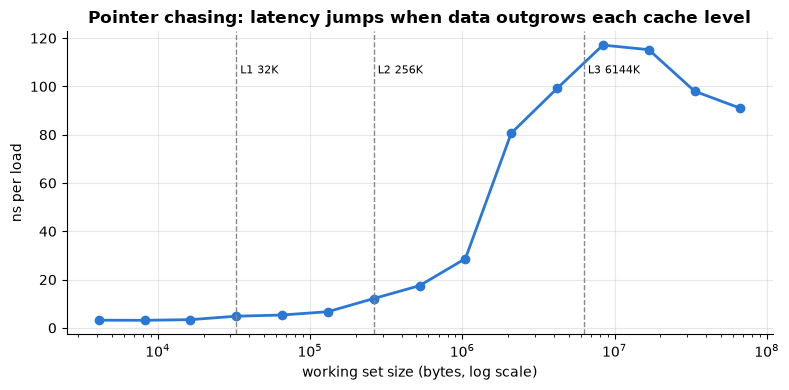

In [13]:
def cache_sizes_from_sys():
    """Read the cache sizes the Linux kernel reports for CPU 0 (empty on other systems)."""
    out = {}
    base = Path("/sys/devices/system/cpu/cpu0/cache")
    for idx in sorted(base.glob("index*")) if base.exists() else []:
        try:
            level, ctype, size = ((idx / f).read_text().strip() for f in ("level", "type", "size"))
            if ctype != "Instruction":
                out[f"L{level}"] = size
        except OSError:
            pass
    return out

reported = cache_sizes_from_sys()
print("cache sizes reported by the OS:", reported or "not available on this system")

if HAVE_NUMBA:
    @njit(cache=False)
    def chase(nxt, steps):
        i = 0
        for _ in range(steps):
            i = nxt[i]                    # the next address depends on this load: no overlap possible
        return i

    def random_cycle(n, rng):
        perm = rng.permutation(n)
        nxt = np.empty(n, dtype=np.int64)
        nxt[perm[:-1]] = perm[1:]; nxt[perm[-1]] = perm[0]
        return nxt

    rng = np.random.default_rng(0)
    chase(random_cycle(16, rng), 10)
    sizes_kb = [4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384, 32768, 65536]
    steps = 2_000_000
    ns_per = []
    for kb in sizes_kb:
        nxt = random_cycle(kb * 1024 // 8, rng)
        ns_per.append(best_time(lambda: chase(nxt, steps), repeat=3) / steps * 1e9)
    probe = pd.DataFrame({"working set (KB)": sizes_kb, "ns per dependent load": np.round(ns_per, 2)})
    print(probe.T.to_string(header=False))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.semilogx(np.array(sizes_kb) * 1024, ns_per, "o-")
    for name, size in reported.items():
        kb = int(size.rstrip("K")) if size.endswith("K") else int(float(size.rstrip("M")) * 1024)
        ax.axvline(kb * 1024, color="#888", ls="--", lw=1); ax.text(kb * 1024, max(ns_per) * 0.9, f" {name} {size}", fontsize=8)
    ax.set_xlabel("working set size (bytes, log scale)"); ax.set_ylabel("ns per load")
    ax.set_title("Pointer chasing: latency jumps when data outgrows each cache level")
    plt.tight_layout(); plt.show()
    assert ns_per[-1] > 5 * ns_per[0]                              # RAM is much slower than L1
else:
    print("numba not installed: skipping the latency probe (a pure-Python loop is too slow to see cache effects)")

**What just happened?** While the working set fits in L1, each dependent load takes only a few nanoseconds; the time per load rises once the array outgrows L1 and again after L2 (dashed lines show the sizes the operating system reports), and in RAM it is many times higher than in L1 (asserted, exact values printed). The biggest jump may come **before** the reported L3 size: the L3 is shared by all cores (with other programs running, each gets only part of it), and at these sizes the random walk also misses in the **TLB**, the small cache of virtual-to-physical address translations. Real measurements are messier than the textbook staircase, which is exactly why we measure.

### 4.2 Row-major vs column-major, strides and contiguity

**Definitions.** NumPy (like C and PyTorch) stores 2-D arrays in **row-major** order (`order="C"`): `a[i, j]` and `a[i, j+1]` are adjacent. Fortran, MATLAB and R use **column-major** order. An array's **strides** say how many bytes to jump to move one step along each axis. A transpose or a slice like `a[:, ::2]` is a **view** with different strides; no data moves. An array is **C-contiguous** if its rows are packed back to back.

In [14]:
a = np.random.rand(2048, 2048)                       # 32 MB of float64, larger than any cache here
print("a.strides   =", a.strides, "  C-contiguous:", a.flags["C_CONTIGUOUS"])
print("a.T.strides =", a.T.strides, "  C-contiguous:", a.T.flags["C_CONTIGUOUS"], " (a view: shares memory with a:", np.shares_memory(a, a.T), ")")

t_rows = best_time(lambda: [a[i, :].sum() for i in range(a.shape[0])], repeat=3)
t_cols = best_time(lambda: [a[:, j].sum() for j in range(a.shape[1])], repeat=3)
aT = np.ascontiguousarray(a.T)                       # pay for one copy so that columns become rows
t_copy = best_time(lambda: np.ascontiguousarray(a.T), repeat=3)
t_cols_after = best_time(lambda: [aT[j, :].sum() for j in range(aT.shape[0])], repeat=3)
print(f"sum each row: {t_rows * 1e3:.1f} ms | sum each column: {t_cols * 1e3:.1f} ms ({t_cols / t_rows:.1f}x slower)")
print(f"np.ascontiguousarray(a.T) costs {t_copy * 1e3:.1f} ms once; columns as rows afterwards: {t_cols_after * 1e3:.1f} ms")

# Stride sweep: read 250,000 doubles that are k elements apart
big = np.random.rand(8 * 1024 * 1024)                # 64 MB, larger than the caches
n = 250_000
rows = []
for k in [1, 2, 4, 8, 16, 32]:
    v = big[: n * k : k]
    rows.append((k, k * 8, best_time(lambda: v.sum()) / n * 1e9))
stride = pd.DataFrame(rows, columns=["stride (elements)", "stride (bytes)", "ns per element"]).round(3)
print(stride.to_string(index=False))
assert stride["ns per element"].iloc[3] > 2 * stride["ns per element"].iloc[0]
del big, a, aT                                        # free the memory

a.strides   = (16384, 8)   C-contiguous: True
a.T.strides = (8, 16384)   C-contiguous: False  (a view: shares memory with a: True )


sum each row: 10.2 ms | sum each column: 47.8 ms (4.7x slower)
np.ascontiguousarray(a.T) costs 50.7 ms once; columns as rows afterwards: 15.9 ms
 stride (elements)  stride (bytes)  ns per element
                 1               8           1.149
                 2              16           2.393
                 4              32           4.789
                 8              64           8.163
                16             128          12.655
                32             256          11.893


**What just happened?**
- The transpose `a.T` cost nothing: it only swapped the strides (`(16384, 8)` became `(8, 16384)`). But walking down columns of a row-major array jumps 16 KB per element, so each element drags in a whole 64-byte cache line of which 8 bytes are used. Summing columns was several times slower than summing rows (exact ratio printed).
- `np.ascontiguousarray` pays for one copy, after which the former columns are contiguous rows; worth it when you access them many times.
- The **stride sweep** reads the same number of elements each time. The cost per element rises steeply up to a stride of 8 doubles = 64 bytes: from there on every read fetches a new cache line for a single useful element. Beyond 64 bytes any further change comes from second-order effects (the hardware prefetcher, and more memory pages touched per element, which costs TLB misses).

⚠️ **Common mistake:** in PyTorch, `x.T`, `x.permute(...)` and some slices are non-contiguous views; `x.view(...)` then fails and some kernels silently make a copy. Call `.contiguous()` once, deliberately, where it pays off.

## 5. SIMD, vectorisation and the roofline model

> 💬 **In plain English:** do many operations per instruction (SIMD) and check whether your code is limited by arithmetic or by memory traffic.

**Intuition.** One instruction can operate on a whole short vector of numbers at once. A modern CPU core with **AVX2** handles 8 float32 values per instruction (256 bits), **AVX-512** 16; ARM CPUs have NEON/SVE. NumPy and compiled code use these instructions; a Python `for` loop handles one Python object at a time, with interpreter work around each one.

**Definition.** **SIMD** = single instruction, multiple data. **Vectorisation** (in NumPy-speak) = expressing a computation as whole-array operations so it runs in compiled, SIMD-friendly loops.

In [15]:
n = 1_000_000
x = np.random.rand(n).astype(np.float32); y = np.random.rand(n).astype(np.float32)
xl, yl = x.tolist(), y.tolist()

def dot_python(a, b):
    s = 0.0
    for u, v in zip(a, b):
        s += u * v
    return s

rows = [("Python loop", best_time(lambda: dot_python(xl, yl), repeat=3)),
        ("NumPy np.dot (BLAS, SIMD)", best_time(lambda: np.dot(x, y)))]
if HAVE_NUMBA:
    @njit(cache=False, fastmath=True)        # fastmath lets the compiler reorder the sum and use SIMD
    def dot_numba(a, b):
        s = np.float32(0.0)
        for i in range(a.size):
            s += a[i] * b[i]
        return s
    dot_numba(x[:8], y[:8])
    rows.append(("numba loop (compiled, fastmath)", best_time(lambda: dot_numba(x, y))))
simd = pd.DataFrame(rows, columns=["implementation", "seconds"])
simd["GFLOP/s"] = 2 * n / simd.seconds / 1e9
simd["speed-up vs Python"] = simd.seconds.iloc[0] / simd.seconds
print(simd.round(4).to_string(index=False))

flags = ""
try:
    flags = next(l for l in Path("/proc/cpuinfo").read_text().splitlines() if l.startswith("flags"))
except (OSError, StopIteration):
    pass
print("SIMD extensions reported by the CPU:", [f for f in ["sse4_2", "avx", "avx2", "fma", "avx512f", "avx512_bf16", "amx_tile"] if f" {f}" in flags] or "unknown on this OS")

                 implementation  seconds  GFLOP/s  speed-up vs Python
                    Python loop   0.0993   0.0201              1.0000
      NumPy np.dot (BLAS, SIMD)   0.0006   3.2481            161.3237
numba loop (compiled, fastmath)   0.0004   4.5859            227.7672
SIMD extensions reported by the CPU: ['sse4_2', 'avx', 'avx2', 'fma']


**What just happened?** The same million multiply-adds ran orders of magnitude faster in NumPy (and numba, if installed) than in the Python loop (exact speed-ups printed). Two effects multiply: no interpreter overhead per element, and SIMD instructions doing several elements per instruction. `fastmath=True` matters for the numba sum: strict IEEE rules forbid reordering a floating-point sum (it changes the rounding), and reordering is exactly what SIMD needs.

### 5.1 The roofline model: compute-bound or memory-bound?

**Definitions (Williams, Waterman & Patterson, 2009).**
- **Arithmetic intensity** $I$ = FLOPs performed ÷ bytes moved to or from main memory.
- A machine has a peak compute rate $P$ (FLOP/s) and a peak memory bandwidth $\beta$ (bytes/s). The attainable performance is
$$\text{performance} \le \min(P,\; I \cdot \beta).$$
- The **ridge point** $I^* = P / \beta$ separates **memory-bound** kernels ($I < I^*$: buy bandwidth, reduce bytes) from **compute-bound** ones ($I > I^*$: buy FLOPs).

**Worked examples (float32, 4 bytes per value):**
- `c = a + b` on $n$ elements: $n$ FLOPs, $12n$ bytes (read 2, write 1) → $I = 1/12 \approx 0.083$.
- $C = AB$ with $n \times n$ matrices: $2n^3$ FLOPs, at least $12 n^2$ bytes (each matrix once) → $I = n/6$; for $n = 1024$, $I \approx 171$.

Below we estimate $P$ (the best matrix-multiply rate we observe) and $\beta$ (from a large array copy) on this machine, then place several kernels on the roofline. We limit NumPy's BLAS library to **one thread** (with `threadpoolctl`), so this is the roofline of a single core; that keeps the measurement stable on a busy machine, and a multi-core roofline has the same shape with both roofs raised.

measured bandwidth ≈ 17.7 GB/s | measured peak ≈ 65.6 GFLOP/s | ridge point ≈ 3.7 FLOP/byte
       kernel  intensity FLOP/byte   bound  achieved GFLOP/s  roofline limit GFLOP/s
        a + b                0.083  memory             0.877                   1.475
        2 * a                0.125  memory             1.332                   2.213
    dot(x, x)                0.500  memory             6.044                   8.852
  matmul n=64               10.667 compute            18.842                  65.619
 matmul n=256               42.667 compute            56.348                  65.619
matmul n=1024              170.667 compute            65.619                  65.619
matmul n=2048              341.333 compute            64.270                  65.619


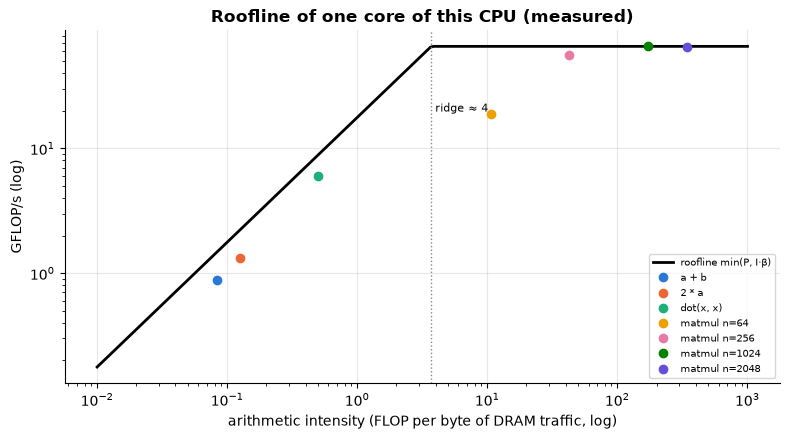

In [16]:
try:
    from threadpoolctl import threadpool_limits
    one_thread = threadpool_limits(limits=1)                # BLAS uses a single core from here on
except ImportError:
    one_thread = None
src = np.ones(16 * 1024 * 1024, dtype=np.float32)          # 64 MB, far bigger than the caches
dst, other = np.empty_like(src), np.ones_like(src)
bw = 2 * src.nbytes / best_time(lambda: np.copyto(dst, src))          # read + write

kernels = []
t = best_time(lambda: np.add(src, other, out=dst)); kernels.append(("a + b", src.size / t, 1 / 12))
t = best_time(lambda: np.multiply(src, 2.0, out=dst)); kernels.append(("2 * a", src.size / t, 1 / 8))
xs = src[: 8 * 1024 * 1024]
t = best_time(lambda: np.dot(xs, xs)); kernels.append(("dot(x, x)", 2 * xs.size / t, 2 / 4))
for m in [64, 256, 1024, 2048]:
    A = np.random.rand(m, m).astype(np.float32); Bm = np.random.rand(m, m).astype(np.float32)
    t = best_time(lambda: A @ Bm, repeat=3); kernels.append((f"matmul n={m}", 2 * m ** 3 / t, m / 6))
peak = max(fl for name, fl, _ in kernels if name.startswith("matmul"))   # best compute rate we observed
ridge = peak / bw
print(f"measured bandwidth ≈ {bw / 1e9:.1f} GB/s | measured peak ≈ {peak / 1e9:.1f} GFLOP/s | ridge point ≈ {ridge:.1f} FLOP/byte")
roof = pd.DataFrame(kernels, columns=["kernel", "FLOP/s", "intensity FLOP/byte"])
roof["bound"] = np.where(roof["intensity FLOP/byte"] < ridge, "memory", "compute")
roof["roofline limit GFLOP/s"] = np.minimum(peak, roof["intensity FLOP/byte"] * bw) / 1e9
roof["achieved GFLOP/s"] = roof["FLOP/s"] / 1e9
print(roof[["kernel", "intensity FLOP/byte", "bound", "achieved GFLOP/s", "roofline limit GFLOP/s"]].round(3).to_string(index=False))

I = np.logspace(-2, 3, 200)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(I, np.minimum(peak, I * bw) / 1e9, "k-", lw=2, label="roofline min(P, I·β)")
ax.axvline(ridge, color="#888", ls=":", lw=1); ax.text(ridge, peak / 1e9 * 0.3, f" ridge ≈ {ridge:.0f}", fontsize=8)
for (name, fl, inten), c in zip(kernels, plt.rcParams["axes.prop_cycle"].by_key()["color"] * 2):
    ax.loglog(inten, fl / 1e9, "o", color=c, label=name)
ax.set_xlabel("arithmetic intensity (FLOP per byte of DRAM traffic, log)"); ax.set_ylabel("GFLOP/s (log)")
ax.set_title("Roofline of one core of this CPU (measured)"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()
assert roof.loc[roof.kernel == "a + b", "bound"].item() == "memory"
if one_thread is not None:
    one_thread.restore_original_limits()                   # give BLAS its threads back

**What just happened?** The black line is the roofline of one core of this machine, built from two measurements: copy bandwidth (the slanted part) and the best matrix-multiply rate (the flat part, so by construction the best matmul point touches it). The elementwise kernels (`a + b`, `2 * a`, dot product) sit far left of the ridge point: they are **memory-bound**, so their GFLOP/s is tiny no matter how fast the arithmetic units are, and the only way to speed them up is to move fewer bytes (fuse operations, use smaller dtypes). Matrix multiplies sit right of the ridge and approach the compute roof; the small one (n = 64) usually falls short because of fixed per-call overheads and too little work to keep the arithmetic units busy. Our intensities are idealised (each matrix read once); real traffic is higher, which is why points can sit below the roof.

🎓 **Interview tip:** "Why is my GPU only 10% utilised?" First compute the arithmetic intensity. If it is below the ridge point, the kernel is memory-bound: fuse operations, reduce precision, or batch more work per byte.

## 6. GPU architecture concepts and transformer arithmetic intensity

> 💬 **In plain English:** GPUs are thousands of simple lanes fed by very fast memory; a layer is fast only if it does enough math per byte.

**Intuition.** A CPU has a few very clever cores (big caches, branch predictors, out-of-order execution) optimised for **latency**. A GPU has thousands of simple lanes optimised for **throughput**: it hides memory latency by keeping many threads in flight and switching to another group whenever one waits.

**Definitions (NVIDIA terminology; AMD uses compute units and wavefronts).**

| Concept | Meaning |
|---|---|
| **SM** (streaming multiprocessor) | the GPU's "core": an H100 SXM has 132 SMs, each with its own registers, L1/shared memory and tensor cores |
| **Warp** | 32 threads that execute the same instruction in lock-step (**SIMT**). If threads in a warp take different branches (**divergence**), both paths run one after the other |
| **Shared memory** | fast on-chip memory (hundreds of KB per SM, shared with L1) that a thread block uses as a programmer-managed cache: this is where tiling (as in FlashAttention) happens |
| **HBM** | high-bandwidth memory on the package: ~2–3.35 TB/s on A100/H100, tens of GB |
| **Coalescing** | when the 32 threads of a warp read consecutive addresses, the hardware merges them into a few wide transactions; scattered reads waste bandwidth (the GPU version of section 4's strides) |
| **Tensor cores** | units that do small matrix multiply-accumulates (e.g. 16×16 tiles) in fp16/bf16/fp8/int8 per instruction; most of a modern GPU's FLOPs live here |
| **Occupancy** | how many warps are resident per SM; more warps hide more memory latency |

Published peak numbers (dense, without sparsity; NVIDIA datasheets): **A100 SXM 80 GB**: 312 TFLOP/s bf16, 2.04 TB/s → ridge ≈ 153 FLOP/byte. **H100 SXM**: ≈ 989 TFLOP/s bf16, 3.35 TB/s → ridge ≈ 295 FLOP/byte. Newer generations raise both numbers, and the ridge stays in the hundreds: a kernel needs **hundreds of FLOPs per byte** to be compute-bound on a modern GPU.

### 6.1 Arithmetic intensity of transformer layers

For a linear layer $Y = XW$ with $T$ tokens, input width $d_{in}$ and output width $d_{out}$, in bf16 (2 bytes):
$$\text{FLOPs} = 2 T d_{in} d_{out}, \qquad \text{bytes} \approx 2\,(T d_{in} + d_{in} d_{out} + T d_{out}).$$
When $T \ll d$, the weight matrix dominates the bytes and $I \approx T$: **intensity grows with the number of tokens processed together**.

- **Prefill** (processing the prompt) handles thousands of tokens at once → compute-bound.
- **Decoding** generates one token per sequence per step → $T$ = batch size, often 1–64 → **memory-bound**: the GPU spends its time reading weights.
- **Attention during decoding** reads each sequence's own **KV cache** ($2 \times$ layers $\times$ context $\times d$ values) to do about 2 FLOPs per value read → $I \approx 1$, memory-bound even with batching, since caches are not shared between sequences.

A100 SXM (bf16): ridge point = 153 FLOP/byte
H100 SXM (bf16): ridge point = 295 FLOP/byte

MLP up-projection 4096 -> 11008 in bf16:
 tokens T  GFLOPs  MB moved  FLOP/byte    A100    H100
        1     0.1      90.2        1.0  memory  memory
        8     0.7      90.4        8.0  memory  memory
       64     5.8      92.1       62.7  memory  memory
      256    23.1      97.9      235.8 compute  memory
     1024    92.3     121.1      762.5 compute compute
     4096   369.4     213.9     1726.7 compute compute

decode attention, one layer, context 4096: intensity = 1.0 FLOP/byte (memory-bound)


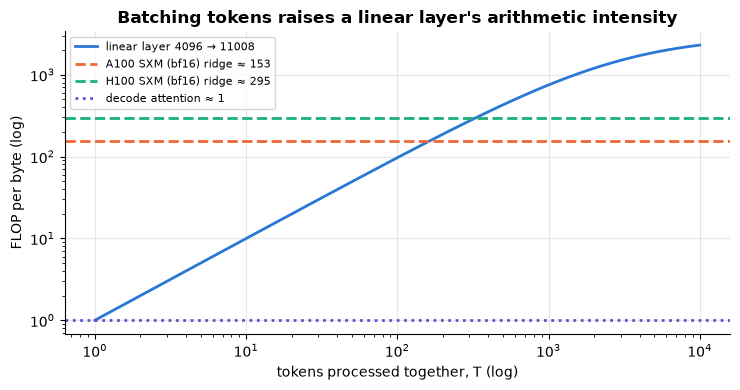

In [17]:
GPUS = {"A100 SXM (bf16)": (312e12, 2.039e12), "H100 SXM (bf16)": (989e12, 3.35e12)}
for g, (P, B) in GPUS.items():
    print(f"{g}: ridge point = {P / B:.0f} FLOP/byte")

def linear_intensity(T, d_in, d_out, bytes_per=2):
    flops = 2 * T * d_in * d_out
    traffic = bytes_per * (T * d_in + d_in * d_out + T * d_out)
    return flops, traffic, flops / traffic

d, d_ff = 4096, 11008                                # widths of a Llama-2-7B-sized block
rows = []
for T in [1, 8, 64, 256, 1024, 4096]:
    f, b, inten = linear_intensity(T, d, d_ff)
    rows.append((T, f / 1e9, b / 1e6, inten,
                 *("compute" if inten > P / B else "memory" for P, B in GPUS.values())))
li = pd.DataFrame(rows, columns=["tokens T", "GFLOPs", "MB moved", "FLOP/byte", "A100", "H100"]).round(1)
print(f"\nMLP up-projection {d} -> {d_ff} in bf16:"); print(li.to_string(index=False))

# Attention during decoding: per new token, read K and V for every previous position
L_ctx = 4096
attn_flops = 2 * 2 * L_ctx * d                         # q·K^T and probabilities·V, 2 FLOPs per multiply-add
attn_bytes = 2 * 2 * L_ctx * d                         # K and V caches in bf16
print(f"\ndecode attention, one layer, context {L_ctx}: intensity = {attn_flops / attn_bytes:.1f} FLOP/byte (memory-bound)")

fig, ax = plt.subplots(figsize=(7.5, 4))
Ts = np.logspace(0, 4, 100)
ax.loglog(Ts, [linear_intensity(T, d, d_ff)[2] for T in Ts], label="linear layer 4096 → 11008")
for (g, (P, B)), c in zip(GPUS.items(), ["#eb6834", "#1baf7a"]):
    ax.axhline(P / B, color=c, ls="--", label=f"{g} ridge ≈ {P / B:.0f}")
ax.axhline(attn_flops / attn_bytes, color="#6250d6", ls=":", label="decode attention ≈ 1")
ax.set_xlabel("tokens processed together, T (log)"); ax.set_ylabel("FLOP per byte (log)")
ax.set_title("Batching tokens raises a linear layer's arithmetic intensity"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?** With one token at a time the linear layer does about **1 FLOP per byte**, hundreds of times below either GPU's ridge point, so its speed is set entirely by HBM bandwidth. Around a few hundred tokens processed together it crosses the A100 ridge (≈ 153) and, a little later, the H100 ridge (≈ 295); the table shows the crossover for this layer. Decode-time attention stays near 1 FLOP/byte whatever the batch size.

This one calculation explains most of LLM inference engineering ([`08_LLM/13_inference_optimization`](../08_LLM/13_inference_optimization.ipynb)):
- **Batching** many users' decode steps together (continuous batching in vLLM/TGI) raises $T$ for the linear layers.
- **Quantising weights** to 8 or 4 bits cuts the bytes per step, which directly speeds up memory-bound decoding.
- **KV-cache** tricks (grouped-query attention, paged attention, KV quantisation) attack the attention reads.
- **Speculative decoding** verifies several draft tokens in one pass, turning $T = 1$ into $T = k$.

A quick upper bound on single-stream decoding speed: every step must read all the weights once.

In [18]:
def decode_tokens_per_s(n_params, bytes_per_param, bandwidth):
    return bandwidth / (n_params * bytes_per_param)              # ignores KV cache and overheads: an upper bound

rows = []
for model, n_params in [("7B (Llama-2-7B, 6.74e9 params)", 6.74e9), ("13B", 13e9)]:
    for prec, bpp in [("bf16", 2), ("int8", 1), ("int4", 0.5)]:
        rows.append((model, prec, n_params * bpp / 1e9, decode_tokens_per_s(n_params, bpp, 3.35e12)))
dec = pd.DataFrame(rows, columns=["model", "weights", "GB per step", "max tokens/s on one H100 (batch 1)"]).round(1)
print(dec.to_string(index=False))
kv_per_token = 2 * 32 * 4096 * 2                                   # K and V, 32 layers, d=4096, bf16
print(f"\nLlama-2-7B KV cache: {kv_per_token / 2**20:.2f} MiB per token -> {kv_per_token * 4096 / 2**30:.1f} GiB for one 4,096-token sequence")

                         model weights  GB per step  max tokens/s on one H100 (batch 1)
7B (Llama-2-7B, 6.74e9 params)    bf16         13.5                               248.5
7B (Llama-2-7B, 6.74e9 params)    int8          6.7                               497.0
7B (Llama-2-7B, 6.74e9 params)    int4          3.4                               994.1
                           13B    bf16         26.0                               128.8
                           13B    int8         13.0                               257.7
                           13B    int4          6.5                               515.4

Llama-2-7B KV cache: 0.50 MiB per token -> 2.0 GiB for one 4,096-token sequence


**What just happened?** At batch 1 an H100 can generate at most about 250 tokens per second from a 7B model in bf16, because each token requires streaming all ~13.5 GB of weights through the memory system; quantising to int4 raises the ceiling about 4×. Meanwhile the KV cache of Llama-2-7B needs 0.5 MiB per token, 2 GiB for a single 4,096-token conversation, which is what limits how many users fit on one GPU. Neither number depends on the GPU's TFLOP/s: decoding is a **memory-bandwidth** problem.

## 7. Measuring your hardware from Python

> 💬 **In plain English:** ask the operating system what hardware you have before you tune for it.

Before tuning, find out what you are running on. The standard library and `psutil` report cores and memory; on Linux, `/sys` and `/proc` add cache sizes and CPU features. Note the difference between **physical cores** and **logical CPUs** (hyper-threading/SMT runs two threads per core, sharing its execution units and caches), and between the machine's CPUs and those **this process may use** (containers and job schedulers restrict them).

In [19]:
info = {"logical CPUs (os.cpu_count)": os.cpu_count()}
if hasattr(os, "sched_getaffinity"):
    info["CPUs this process may use"] = len(os.sched_getaffinity(0))
try:
    import psutil
    info["physical cores (psutil)"] = psutil.cpu_count(logical=False)
    freq = psutil.cpu_freq()
    if freq:
        info["CPU frequency now / max (MHz)"] = f"{freq.current:.0f} / {freq.max:.0f}"
    info["RAM total (GB)"] = round(psutil.virtual_memory().total / 1e9, 1)
    info["CPU load right now (%)"] = psutil.cpu_percent(interval=0.5)
except ImportError:
    info["psutil"] = "not installed"
try:
    info["CPU model"] = next(l.split(":", 1)[1].strip() for l in Path("/proc/cpuinfo").read_text().splitlines() if l.startswith("model name"))
except (OSError, StopIteration):
    info["CPU model"] = platform.processor() or "unknown"
info["architecture"] = platform.machine()
info["caches (OS)"] = cache_sizes_from_sys() or "unknown"
info["CUDA GPU available (torch)"] = torch.cuda.is_available() if HAVE_TORCH else "torch not installed"
for k, v in info.items():
    print(f"{k:32s} {v}")

logical CPUs (os.cpu_count)      8
CPUs this process may use        8
physical cores (psutil)          4
CPU frequency now / max (MHz)    2400 / 4200
RAM total (GB)                   24.8
CPU load right now (%)           48.2
CPU model                        Intel(R) Core(TM) i5-10210U CPU @ 1.60GHz
architecture                     x86_64
caches (OS)                      {'L1': '32K', 'L2': '256K', 'L3': '6144K'}
CUDA GPU available (torch)       False


**What just happened?** You now have the facts the rest of this notebook measured indirectly: how many cores can run in parallel, how big each cache is, and whether a GPU is present. A high "CPU load right now" explains noisy timings: other programs are competing for the same cores and memory bandwidth.

⚠️ **Common mistake:** setting the number of worker threads or processes to `os.cpu_count()` inside a container or on a shared server. Use `len(os.sched_getaffinity(0))` (Linux), and remember that NumPy/PyTorch already use several threads internally: 8 processes × 8 BLAS threads on 8 cores means 64 threads fighting for the same cores ("oversubscription").

## 8. A performance checklist for AI code

> 💬 **In plain English:** a short list of habits that make AI code fast on real hardware, each one measured.

| # | Habit | Why (hardware reason) |
|---|---|---|
| 1 | **Batch** calls (predict on a matrix, not row by row) | amortises per-call overhead; raises arithmetic intensity |
| 2 | **Vectorise**: whole-array NumPy/PyTorch operations instead of Python loops | no interpreter overhead, SIMD/tensor cores |
| 3 | **Keep data contiguous** and traverse it in memory order | full use of every cache line; prefetching |
| 4 | **Avoid copies**: in-place operations, views, `out=` arguments | memory traffic and peak RAM |
| 5 | **Pick the dtype deliberately**: float32/bf16 instead of float64, int8/int4 for inference | fewer bytes moved, faster units |
| 6 | **Fuse** element-wise steps (`torch.compile`, numexpr, numba) | memory-bound chains read and write the data once instead of many times |
| 7 | **Measure first** (profilers, roofline thinking) | optimise the real bottleneck ([`04_debugging_and_profiling`](04_debugging_and_profiling.ipynb)) |

Each of the first five, measured:

In [20]:
from sklearn.linear_model import LogisticRegression
rng = np.random.default_rng(0)
Xtr, ytr = rng.normal(size=(2000, 20)), rng.integers(0, 2, 2000)
clf = LogisticRegression(max_iter=200).fit(Xtr, ytr)
Xq = rng.normal(size=(2000, 20))
results = []

t_row = best_time(lambda: [clf.predict_proba(Xq[i:i + 1]) for i in range(len(Xq))], repeat=2)
t_batch = best_time(lambda: clf.predict_proba(Xq))
results.append(("1 batch: 2,000 predictions row-by-row vs one batch", t_row, t_batch))

v = rng.random(1_000_000)
t_loop = best_time(lambda: [math.sqrt(e) for e in v.tolist()], repeat=2)
t_vec = best_time(lambda: np.sqrt(v))
results.append(("2 vectorise: sqrt of 1M values, Python vs NumPy", t_loop, t_vec))

P1 = rng.random((3000, 3000)).astype(np.float32); P2 = rng.random((3000, 3000)).astype(np.float32)
out = np.empty_like(P1)
P2T = np.ascontiguousarray(P2.T)                                  # the same values as P2.T, stored row by row
t_bad = best_time(lambda: np.add(P1, P2.T, out=out))              # P2.T is a view: read down columns
t_good = best_time(lambda: np.add(P1, P2T, out=out))
results.append(("3 contiguous: P1 + P2.T with a transposed view vs a contiguous copy", t_bad, t_good))

def peak_mb(fn):
    tracemalloc.start(); fn(); peak = tracemalloc.get_traced_memory()[1]; tracemalloc.stop()
    return peak / 1e6
w1 = rng.random(5_000_000)
def chain_copies():
    doubled = w1 * 2.0                                             # each named step keeps a new 40 MB array alive
    shifted = doubled + 1.0
    squared = shifted ** 2
    return squared
def chain_inplace():
    out = w1 * 2.0                                                 # one allocation, then in place
    np.add(out, 1.0, out=out); np.square(out, out=out)
    return out
assert np.allclose(chain_copies(), chain_inplace())
results.append(("4 avoid copies: peak MB for (2w + 1)^2, temporaries vs in-place", peak_mb(chain_copies), peak_mb(chain_inplace)))

A64 = rng.random((1500, 1500)); A32 = A64.astype(np.float32)
t64 = best_time(lambda: A64 @ A64, repeat=3); t32 = best_time(lambda: A32 @ A32, repeat=3)
results.append(("5 dtype: 1500x1500 matmul float64 vs float32", t64, t32))

chk = pd.DataFrame(results, columns=["habit", "before", "after"])
chk["improvement"] = (chk.before / chk.after).round(1).astype(str) + "x"
print(chk.to_string(index=False, formatters={"before": "{:.4g}".format, "after": "{:.4g}".format}))
print("(times in seconds, except row 4, which is peak memory in MB)")
print(f"float32 also halves memory: {A64.nbytes / 1e6:.0f} MB -> {A32.nbytes / 1e6:.0f} MB")

                                                              habit  before     after improvement
                 1 batch: 2,000 predictions row-by-row vs one batch  0.3613 0.0002606     1386.3x
                    2 vectorise: sqrt of 1M values, Python vs NumPy  0.1426  0.001479       96.4x
3 contiguous: P1 + P2.T with a transposed view vs a contiguous copy 0.02252  0.008747        2.6x
    4 avoid copies: peak MB for (2w + 1)^2, temporaries vs in-place     120        40        3.0x
                       5 dtype: 1500x1500 matmul float64 vs float32  0.1334    0.0588        2.3x
(times in seconds, except row 4, which is peak memory in MB)
float32 also halves memory: 18 MB -> 9 MB


**What just happened?** Every habit paid off on this machine (the "improvement" column; exact factors vary between runs and machines). Batching and vectorising give the biggest wins because Python-level overhead per call or per element dwarfs the actual arithmetic. Adding a transposed **view** reads one operand down its columns, one element per cache line, the same effect as in section 4; a contiguous copy (made once, reused many times) avoids it. Writing $(2w+1)^2$ with named intermediate variables keeps three 40 MB arrays alive at once, while the in-place version needs one. (For a single chained expression such as `((w * 2) + 1) ** 2`, NumPy already reuses temporaries automatically, an optimisation called *temporary elision*.) float32 halves the bytes and lets SIMD units process twice as many values per instruction.

## 🔗 How this connects to modern AI

| Hardware idea | AI technique built on it |
|---|---|
| Number formats | bf16/fp8 mixed-precision training, int8/int4 LLM quantisation (GPTQ, AWQ, GGUF), FP8 on H100-class GPUs ([`05_Deep_Learning/13`](../05_Deep_Learning/13_quantization_and_compression_advanced.ipynb)) |
| Memory hierarchy + tiling | **FlashAttention**: tiles attention so it never writes the $n \times n$ matrix to HBM; an "IO-aware" algorithm |
| Roofline / arithmetic intensity | continuous batching, speculative decoding, and why decoding speed scales with memory bandwidth ([`08_LLM/13`](../08_LLM/13_inference_optimization.ipynb)) |
| KV-cache size | grouped-query / multi-query attention, paged attention (vLLM), KV-cache quantisation |
| SIMD on CPUs | llama.cpp and ONNX Runtime run quantised models on laptops using AVX2/AVX-512/NEON |
| Interconnects and collectives | ring all-reduce over NVLink/InfiniBand in multi-GPU training ([`05_Deep_Learning/11`](../05_Deep_Learning/11_distributed_training.ipynb), [`advanced_algorithms/10`](../00_AI_Fundamentals/advanced_algorithms/10_parallel_and_external_memory_algorithms.ipynb)) |
| Logic gates and perceptrons | the 1940s–60s origin of neural networks (McCulloch–Pitts neurons, Rosenblatt's perceptron) and the XOR argument for hidden layers |

## Recap

- Integers use **two's complement** (one adder for signed and unsigned; overflow wraps). Floats are **sign, exponent, mantissa**: the exponent bits set the range, the mantissa bits the precision. bf16 = fp32's range with 8 bits of precision; fp16 = more precision but max 65,504.
- **NAND** builds every gate; full adders build adders and an **ALU** whose flags drive comparisons and branches. A perceptron is a trainable soft gate, and XOR needs two layers.
- CPUs **fetch, decode, execute**; **pipelines** overlap instructions, and **hazards** (load-use, branches) stall them. Unpredictable branches cost real time; branchless or vectorised code avoids it.
- Memory is a **hierarchy** with 64-byte **cache lines**: access data in memory order, reuse it while it is cached, mind **strides** and **contiguity**.
- **SIMD** and vectorised libraries do many operations per instruction. The **roofline** $\min(P, I\beta)$ tells you whether a kernel is compute-bound or memory-bound.
- GPUs have very high bandwidth and huge FLOP rates, with ridge points in the hundreds of FLOPs per byte. LLM **decoding is memory-bound**; prefill is compute-bound.
- Measure your hardware, then batch, vectorise, keep data contiguous, avoid copies, choose the dtype and fuse operations.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy)** Write −20 in 8-bit two's complement. What is the int8 range? What does NumPy return for `np.array([100], dtype=np.int8) * 2`?

<details><summary>Show solution</summary>

$20 = $ `00010100`; flip → `11101011`; add 1 → **`11101100`** (`0xEC`). Range −128 … 127. $100 \times 2 = 200$ does not fit; $200 - 256 = $ **−56** (wrap-around, no error for arrays).

</details>

**2. (Easy, coding)** Decode the fp32 bit pattern `0x40490FDB` by hand-written code (no `struct` for the decoding itself). Which famous number is it?

<details><summary>Show solution</summary>

Sign 0, exponent `0x80` = 128 → $2^1$, fraction `0x490FDB` → $1.5707963…$; value ≈ **3.1415927 (π)**.

```python
import struct

def decode_fp32_hex(h):
    """Value of the fp32 number with bit pattern h (an int such as 0x40490FDB)."""
    s, e, f = h >> 31, (h >> 23) & 0xFF, h & 0x7FFFFF
    assert 0 < e < 255, "this simple version handles normal numbers only"
    return (-1) ** s * (1 + f / 2 ** 23) * 2.0 ** (e - 127)
```
Tested against `struct` on 1,000 random floats.

</details>

**3. (Medium)** An element-wise ReLU on a 1 GB fp16 tensor (read once, write once): what is its arithmetic intensity, and roughly how long does it take on an H100 (3.35 TB/s)? Is it compute- or memory-bound?

<details><summary>Show solution</summary>

1 operation per element, 2 bytes read + 2 bytes written → $I = 0.25$ FLOP/byte, roughly 1000× below the ridge point (≈ 295): **memory-bound**. Time ≈ 2 GB / 3.35 TB/s ≈ **0.6 ms**. The cure is fusion: apply the ReLU inside the preceding matmul kernel so the tensor is written only once.

</details>

**4. (Medium, coding)** Build a 16-bit **Kogge–Stone** carry-lookahead adder: compute each bit's generate $g_i = a_i b_i$ and propagate $p_i = a_i \oplus b_i$, combine pairs with $(G, P) \circ (G', P') = (G \lor (P \land G'), P \land P')$ in a parallel prefix scan, and form the sum. How many levels does it need compared with a ripple adder's 16 carry steps?

<details><summary>Show solution</summary>

```python
def kogge_stone_add(x, y, n=16):
    """n-bit addition with carries from a parallel prefix (Kogge-Stone) scan over (generate, propagate) pairs."""
    g = [((x >> i) & (y >> i)) & 1 for i in range(n)]       # bit i generates a carry
    p = [((x >> i) ^ (y >> i)) & 1 for i in range(n)]       # bit i propagates an incoming carry
    G, P = g[:], p[:]
    d, levels = 1, 0
    while d < n:                                            # log2(n) levels; every position updates in parallel
        G, P = ([G[i] | (P[i] & G[i - d]) if i >= d else G[i] for i in range(n)],
                [P[i] & P[i - d] if i >= d else P[i] for i in range(n)])
        d, levels = 2 * d, levels + 1
    carries = [0] + G[:-1]                                  # carry INTO bit i = group generate of bits 0..i-1
    s = sum(((p[i] ^ carries[i]) << i) for i in range(n))
    return s, G[-1], levels                                 # sum mod 2^n, carry out, gate levels used
```
$\log_2 16 = $ **4** levels instead of 16 sequential carry steps: the (generate, propagate) operator is associative, so the carries are a prefix scan, exactly the Hillis–Steele pattern of [`advanced_algorithms/10`](../00_AI_Fundamentals/advanced_algorithms/10_parallel_and_external_memory_algorithms.ipynb). Tested on 5,000 random pairs.

</details>

**5. (Medium, coding)** Write `bf16_bits(x)` returning the 16-bit bf16 pattern of float32 values with **round-to-nearest-even**, and check the two "exactly halfway" cases 1.00390625 and 1.01171875.

<details><summary>Show solution</summary>

Add `0x7FFF` plus the lowest kept bit, then drop the low 16 bits: halfway cases round to the neighbour whose last bit is 0.

```python
import numpy as np

def bf16_bits(x):
    """bf16 bit pattern (uint16) of float32 values, round-to-nearest-even; NaN kept as a quiet NaN."""
    b = np.asarray(x, dtype=np.float32).view(np.uint32).astype(np.uint64)
    rounded = ((b + 0x7FFF + ((b >> 16) & 1)) >> 16).astype(np.uint16)
    nan = np.isnan(np.asarray(x, dtype=np.float32))
    return np.where(nan, np.uint16(0x7FC0), rounded)
```
`1.00390625` is halfway between bf16 `0x3F80` (1.0) and `0x3F81`; the even one is `0x3F80`. `1.01171875` is halfway between `0x3F81` and `0x3F82`; the even one is `0x3F82`. Matches `torch.bfloat16` on 5,000 random values when torch is installed.

</details>

**6. (Medium)** Estimate the maximum single-stream decoding speed of a 13B-parameter model on one H100 (3.35 TB/s) in bf16 and in int4, ignoring the KV cache. Why does batching 32 users together barely slow each user down?

<details><summary>Show solution</summary>

bf16: $13 \times 10^9 \times 2$ B = 26 GB per token → 3.35 TB/s / 26 GB ≈ **129 tokens/s**. int4: 6.5 GB → ≈ **515 tokens/s**. With 32 users batched, each decoding step still reads the weights **once** but does 32× the FLOPs, so intensity rises from ~1 to ~32 FLOP/byte, still below the ridge point: the step time is almost unchanged while total throughput grows ~32× (until the KV-cache reads and the compute roof start to bite).

</details>

**7. (Hard, conceptual)** In section 3.3, why did we write the kept values to `out[k]` instead of just adding them to a sum? Give two ways to remove the branch-misprediction penalty without sorting.

<details><summary>Show solution</summary>

With a simple `if x >= 128: s += x`, compilers (LLVM in numba) turn the branch into a **conditional move** or a SIMD **masked add**, which has no branch to mispredict, so sorted and unsorted run at the same speed and the demo shows nothing. The data-dependent store index `k` forces a real branch. Fixes: (1) **branchless arithmetic**: `out[k] = x; k += (x >= 128)` (always store, conditionally advance); (2) **vectorised masking**: `data[data >= 128]` or `np.where`, which processes elements in SIMD lanes with masks. On GPUs the same issue appears as **warp divergence**, with the same cure: replace branches by masks.

</details>

## Further reading

- D. A. Patterson & J. L. Hennessy, *Computer Organization and Design: The Hardware/Software Interface* (RISC-V edition, 2nd ed., 2020): ch. 2 (instructions), 3 (arithmetic, IEEE 754), 4 (the processor and pipelining), 5 (memory hierarchy), 6 (parallel processors and GPUs).
- R. E. Bryant & D. R. O'Hallaron, *Computer Systems: A Programmer's Perspective* (3rd ed., 2016): ch. 2 (representing numbers), 4 (processor architecture), 5 (optimising program performance), 6 (the memory hierarchy).
- J. L. Hennessy & D. A. Patterson, *Computer Architecture: A Quantitative Approach* (6th ed., 2017): ch. 4 (data-level parallelism, SIMD and GPUs) and ch. 7 (domain-specific architectures, including TPUs).
- S. Williams, A. Waterman & D. Patterson, "Roofline: an insightful visual performance model for multicore architectures", *CACM* 2009; U. Drepper, "What Every Programmer Should Know About Memory" (2007, free PDF).
- T. Dao et al., "FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness", NeurIPS 2022; P. Micikevicius et al., "Mixed Precision Training", ICLR 2018.
- Free online: Horace He, ["Making Deep Learning Go Brrrr From First Principles"](https://horace.io/brrr_intro.html) (compute-, memory- and overhead-bound) and the [NVIDIA CUDA C++ Programming Guide](https://docs.nvidia.com/cuda/cuda-c-programming-guide/) (SIMT, warps, memory hierarchy).

## Next notebook
➡️ This is the last notebook of the Software Engineering module. Continue with the research track: [`24_Research_Methods/01` · Research methodology and literature review](../24_Research_Methods/01_research_methodology_and_literature_review.ipynb), or go deeper into algorithms with [`advanced_algorithms/10` · Parallel and external-memory algorithms](../00_AI_Fundamentals/advanced_algorithms/10_parallel_and_external_memory_algorithms.ipynb).

⬅️ Previous: [11 · Industry: building and shipping an AI feature](11_industry_building_and_shipping_an_ai_feature.ipynb)